In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [4]:
df= pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [5]:
df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [6]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [8]:
df[pd.to_numeric(df["TotalCharges"], errors="coerce").isna()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [9]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [10]:
df['TotalCharges'].isna().sum()

np.int64(11)

In [11]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


In [12]:
df[df["TotalCharges"].isna()][
    ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


In [13]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [14]:
df['TotalCharges'].isna().sum()

np.int64(0)

In [15]:
df["Churn"].value_counts(normalize=True)* 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

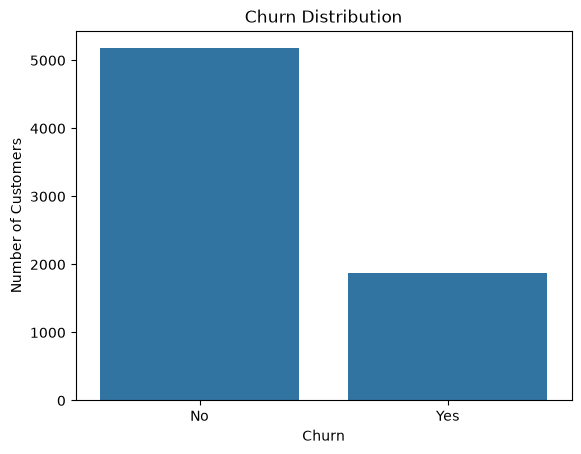

In [16]:

sns.countplot(data=df, x="Churn")
plt.title("Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

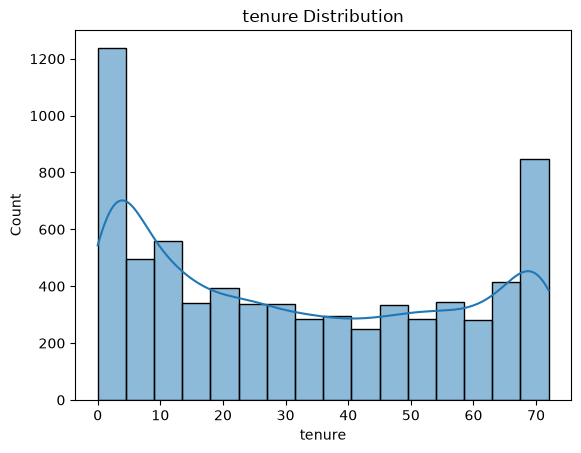

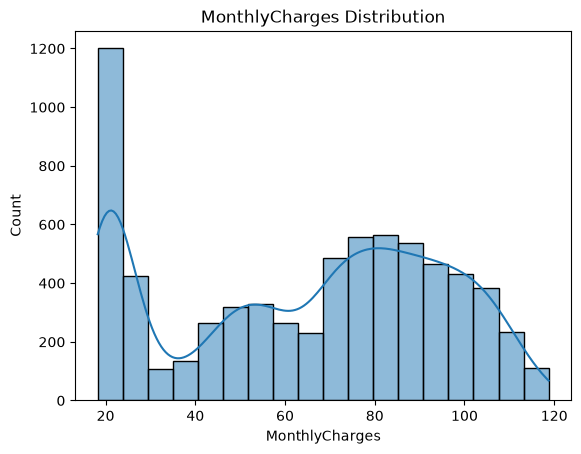

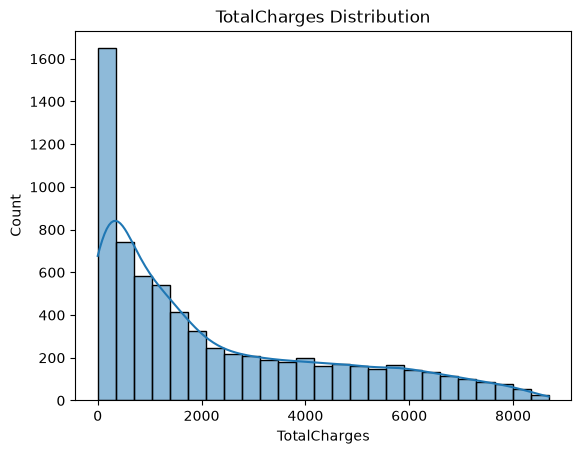

In [17]:

numerical_features = ["tenure", "MonthlyCharges", "TotalCharges"]

for feature in numerical_features:
    sns.histplot(data=df, x=feature, kde=True)
    plt.title(f"{feature} Distribution")
    plt.show()

this  More clearly

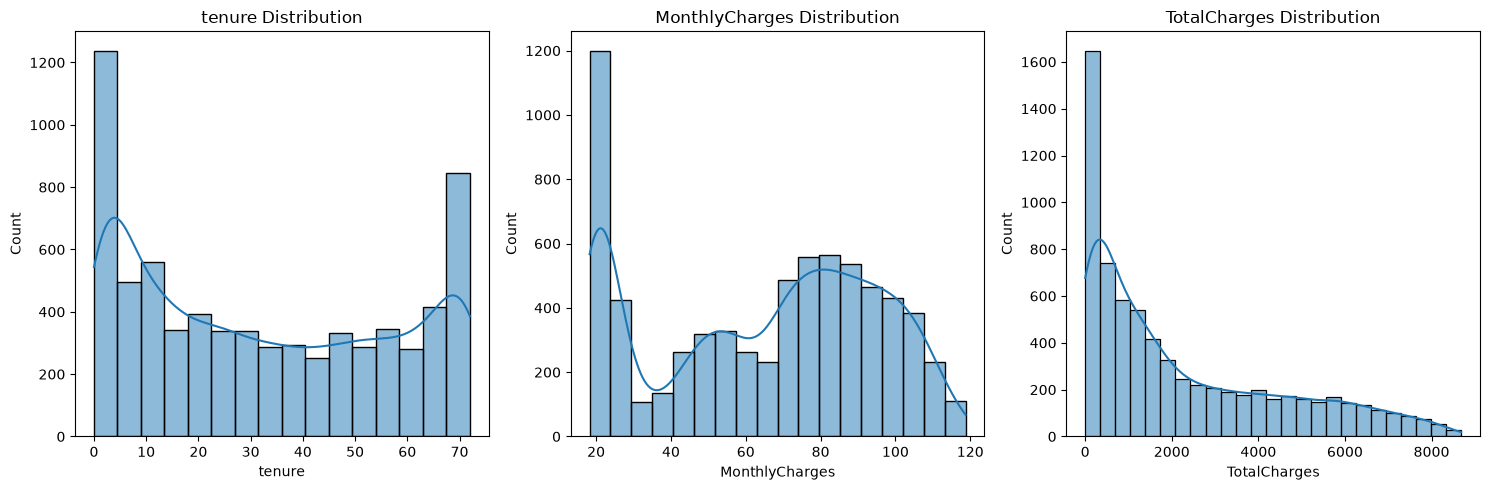

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, feature in enumerate(numerical_features):
    sns.histplot(data=df, x=feature, kde=True, ax=axes[i])
    axes[i].set_title(f"{feature} Distribution")

plt.tight_layout()
plt.show()

In [19]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [20]:
categorical_features = [
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod",
    "SeniorCitizen"
]
print(len(categorical_features))

16


 categorical_features Distribution

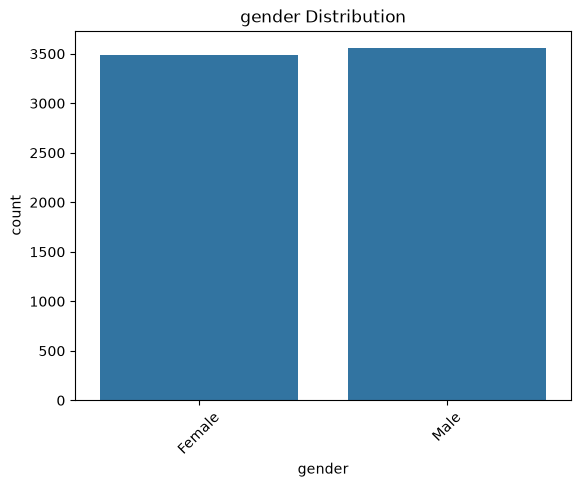

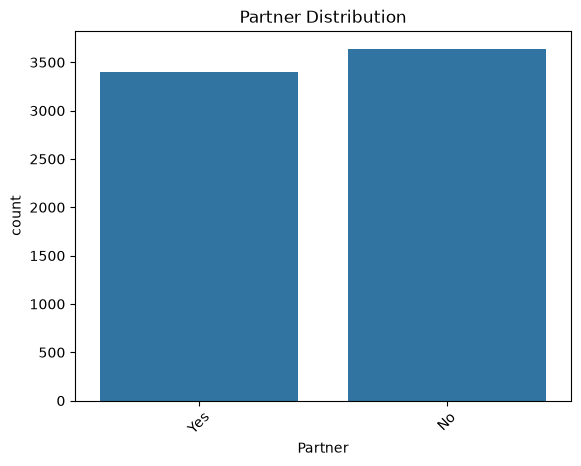

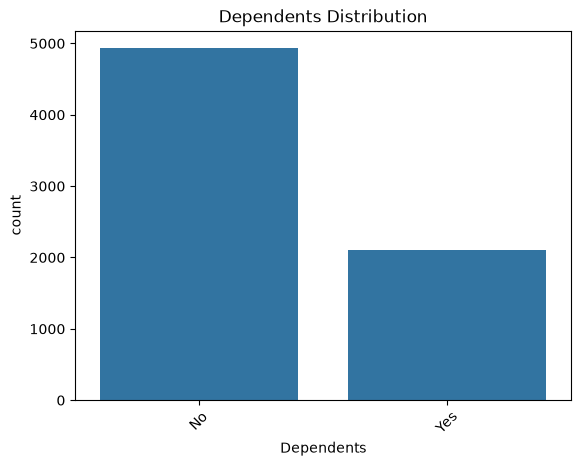

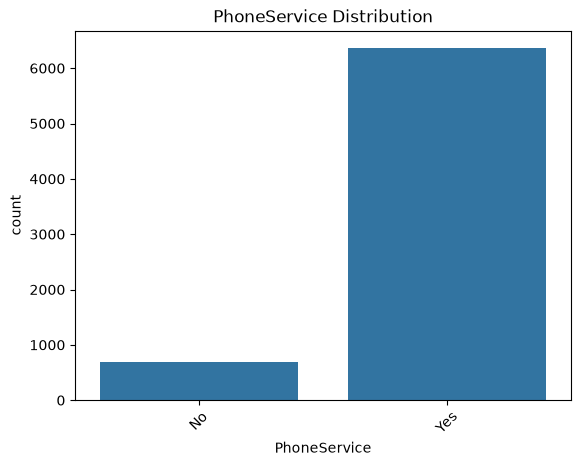

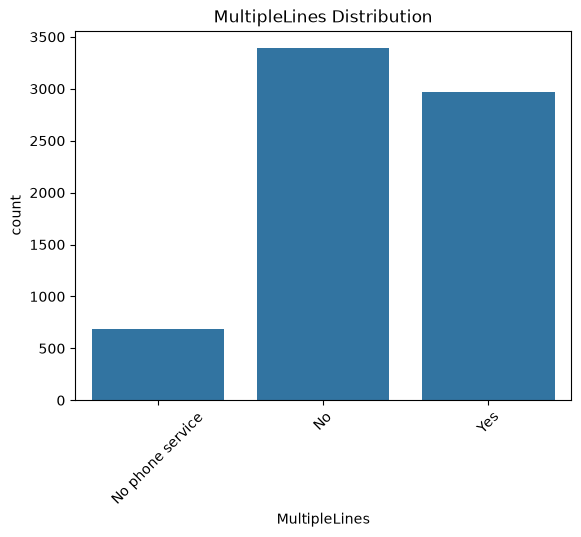

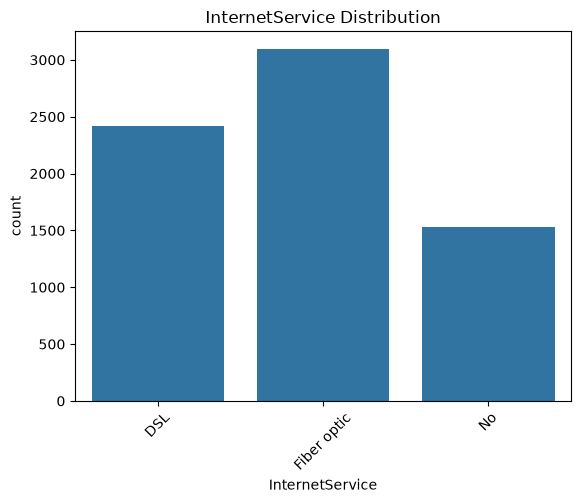

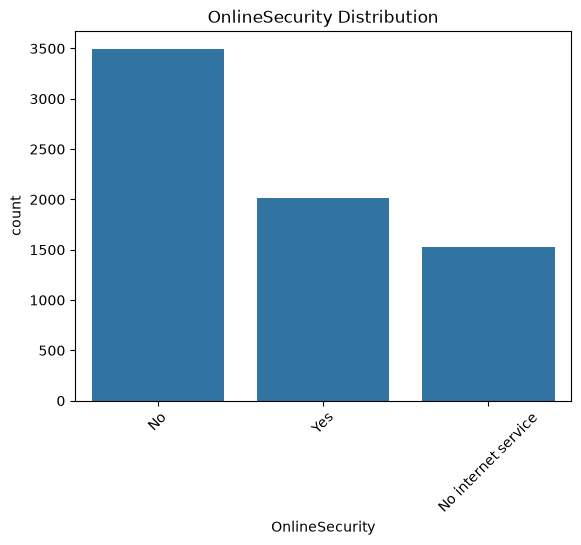

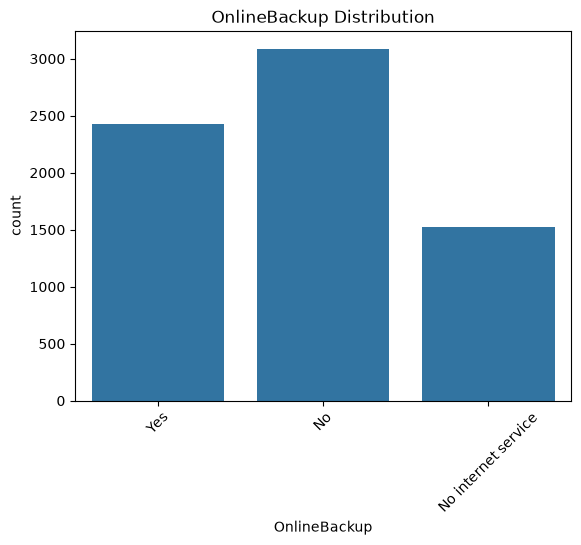

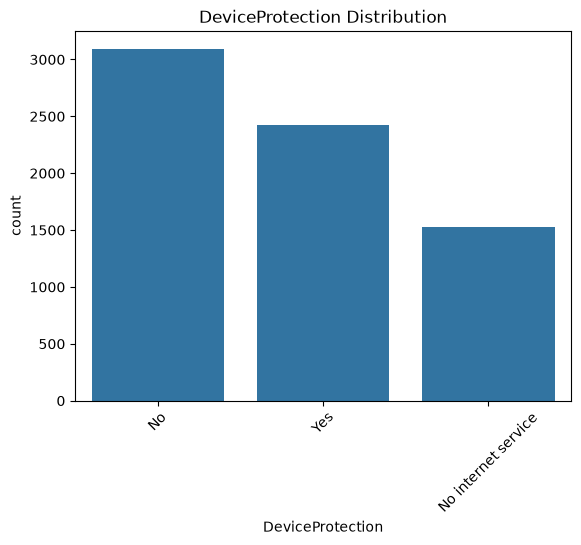

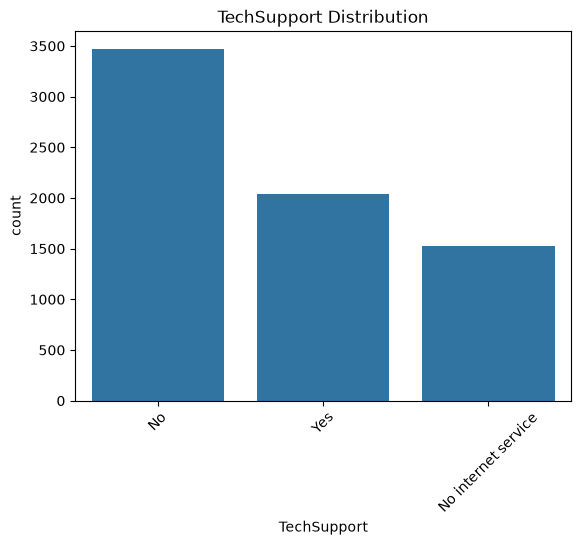

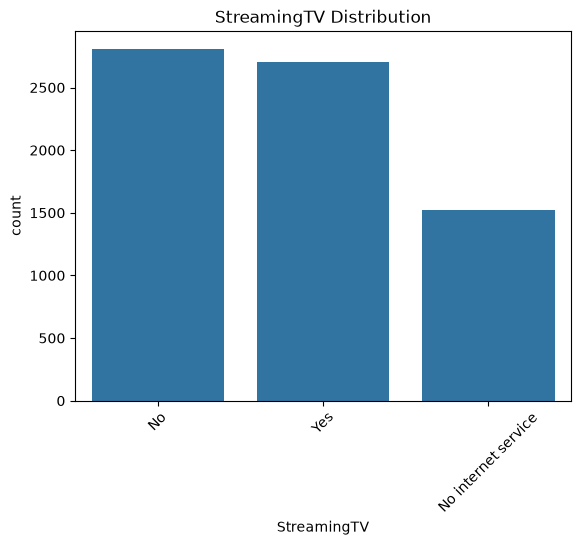

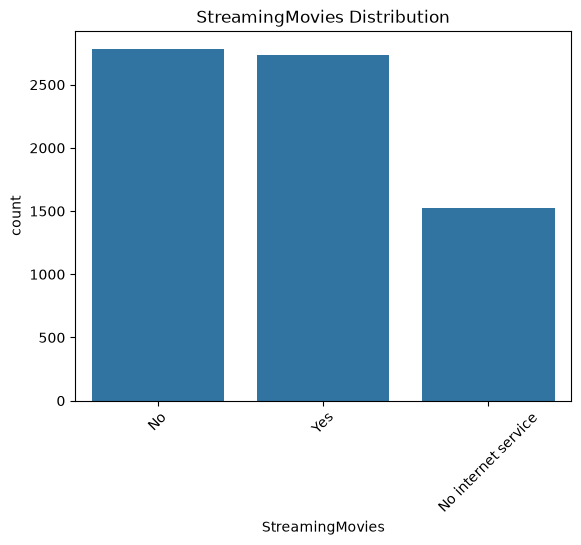

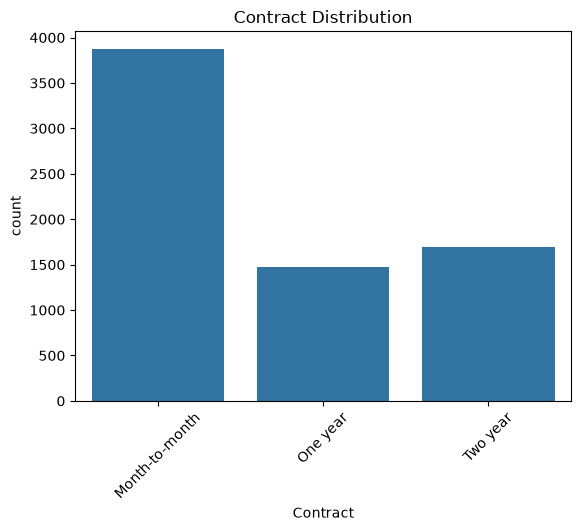

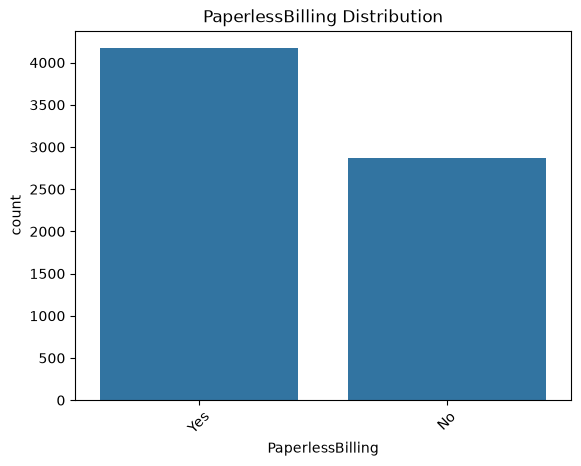

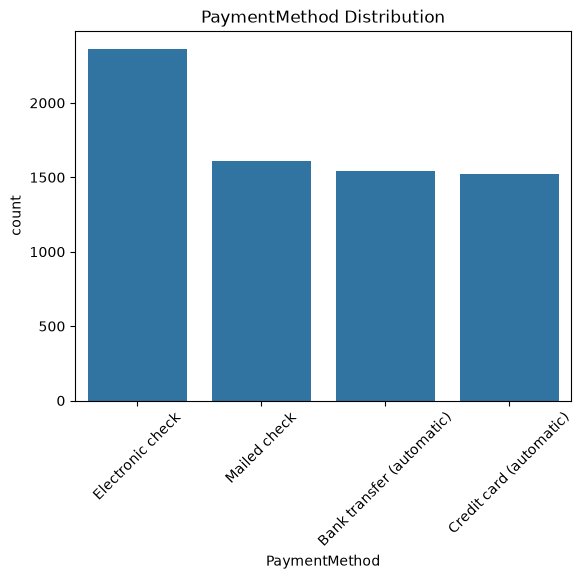

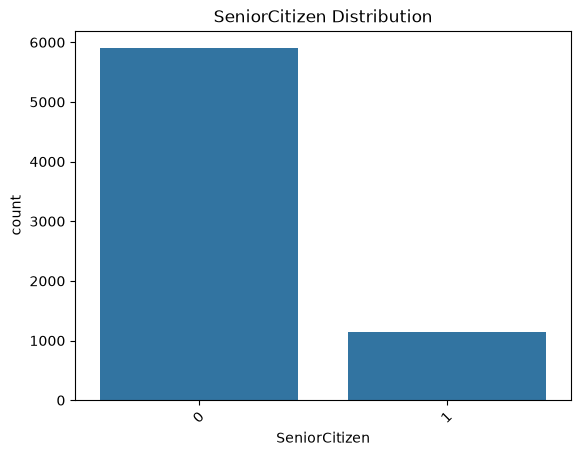

In [21]:
for feature in categorical_features:
    sns.countplot(data=df, x=feature)
    plt.title(f"{feature} Distribution")
    plt.xticks(rotation=45)
    plt.show()

this is categorical_features Distribution But More clearly

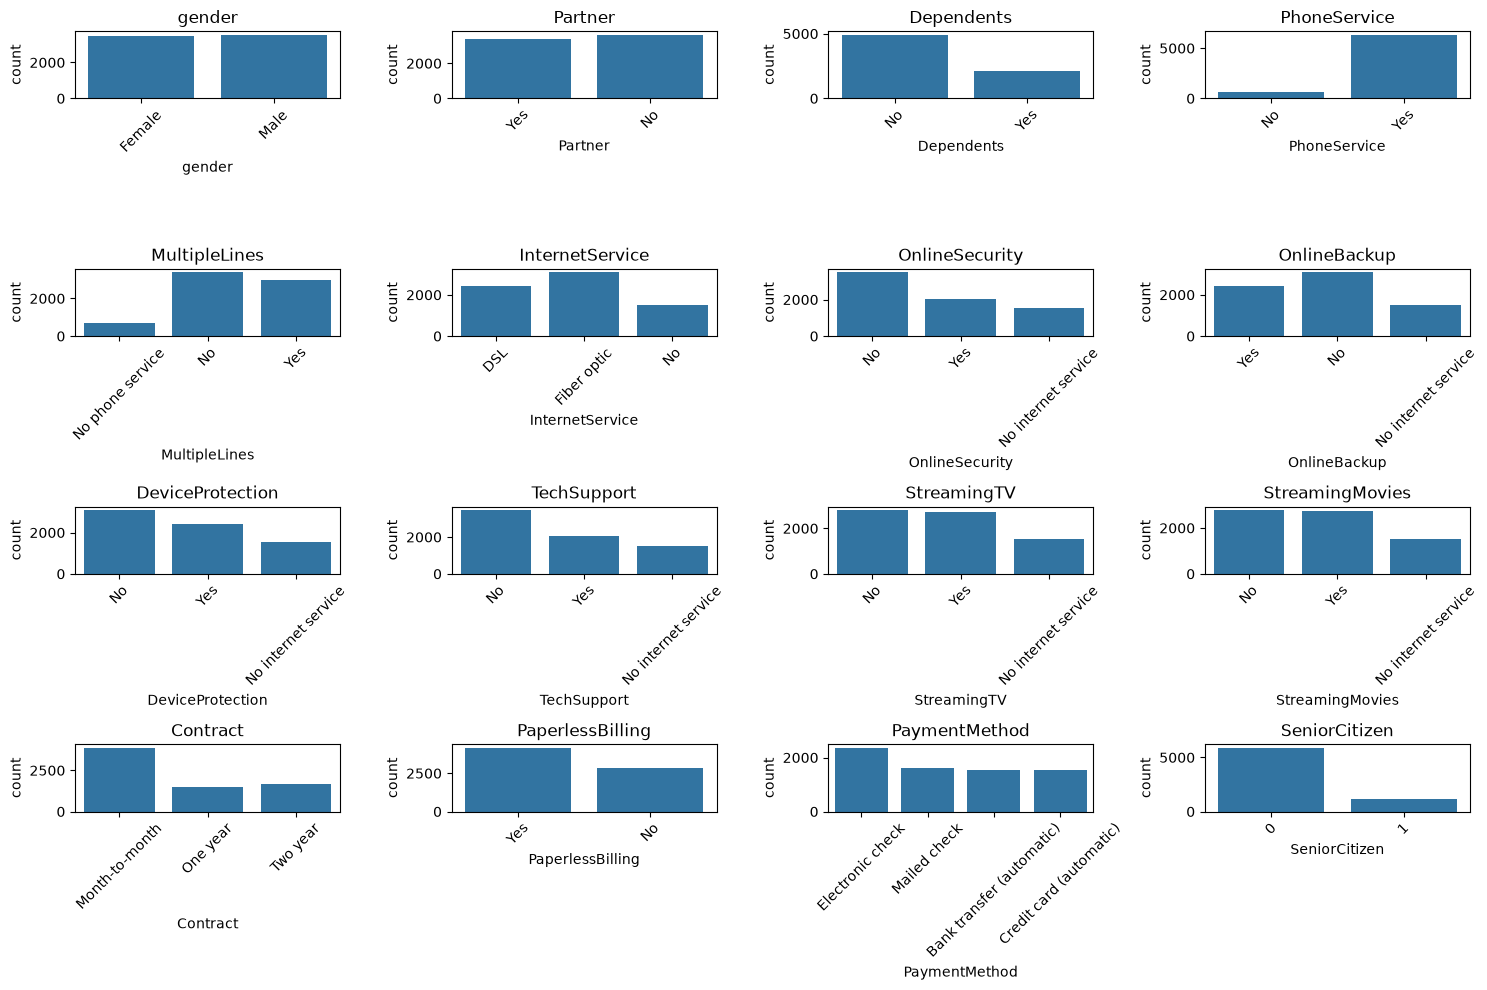

In [22]:
fig, axes = plt.subplots(4, 4, figsize=(15, 10))

for i, feature in enumerate(categorical_features):
    sns.countplot(data=df, x=feature, ax=axes.flat[i])
    axes.flat[i].set_title(feature)
    axes.flat[i].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

categorical_features VS churn 

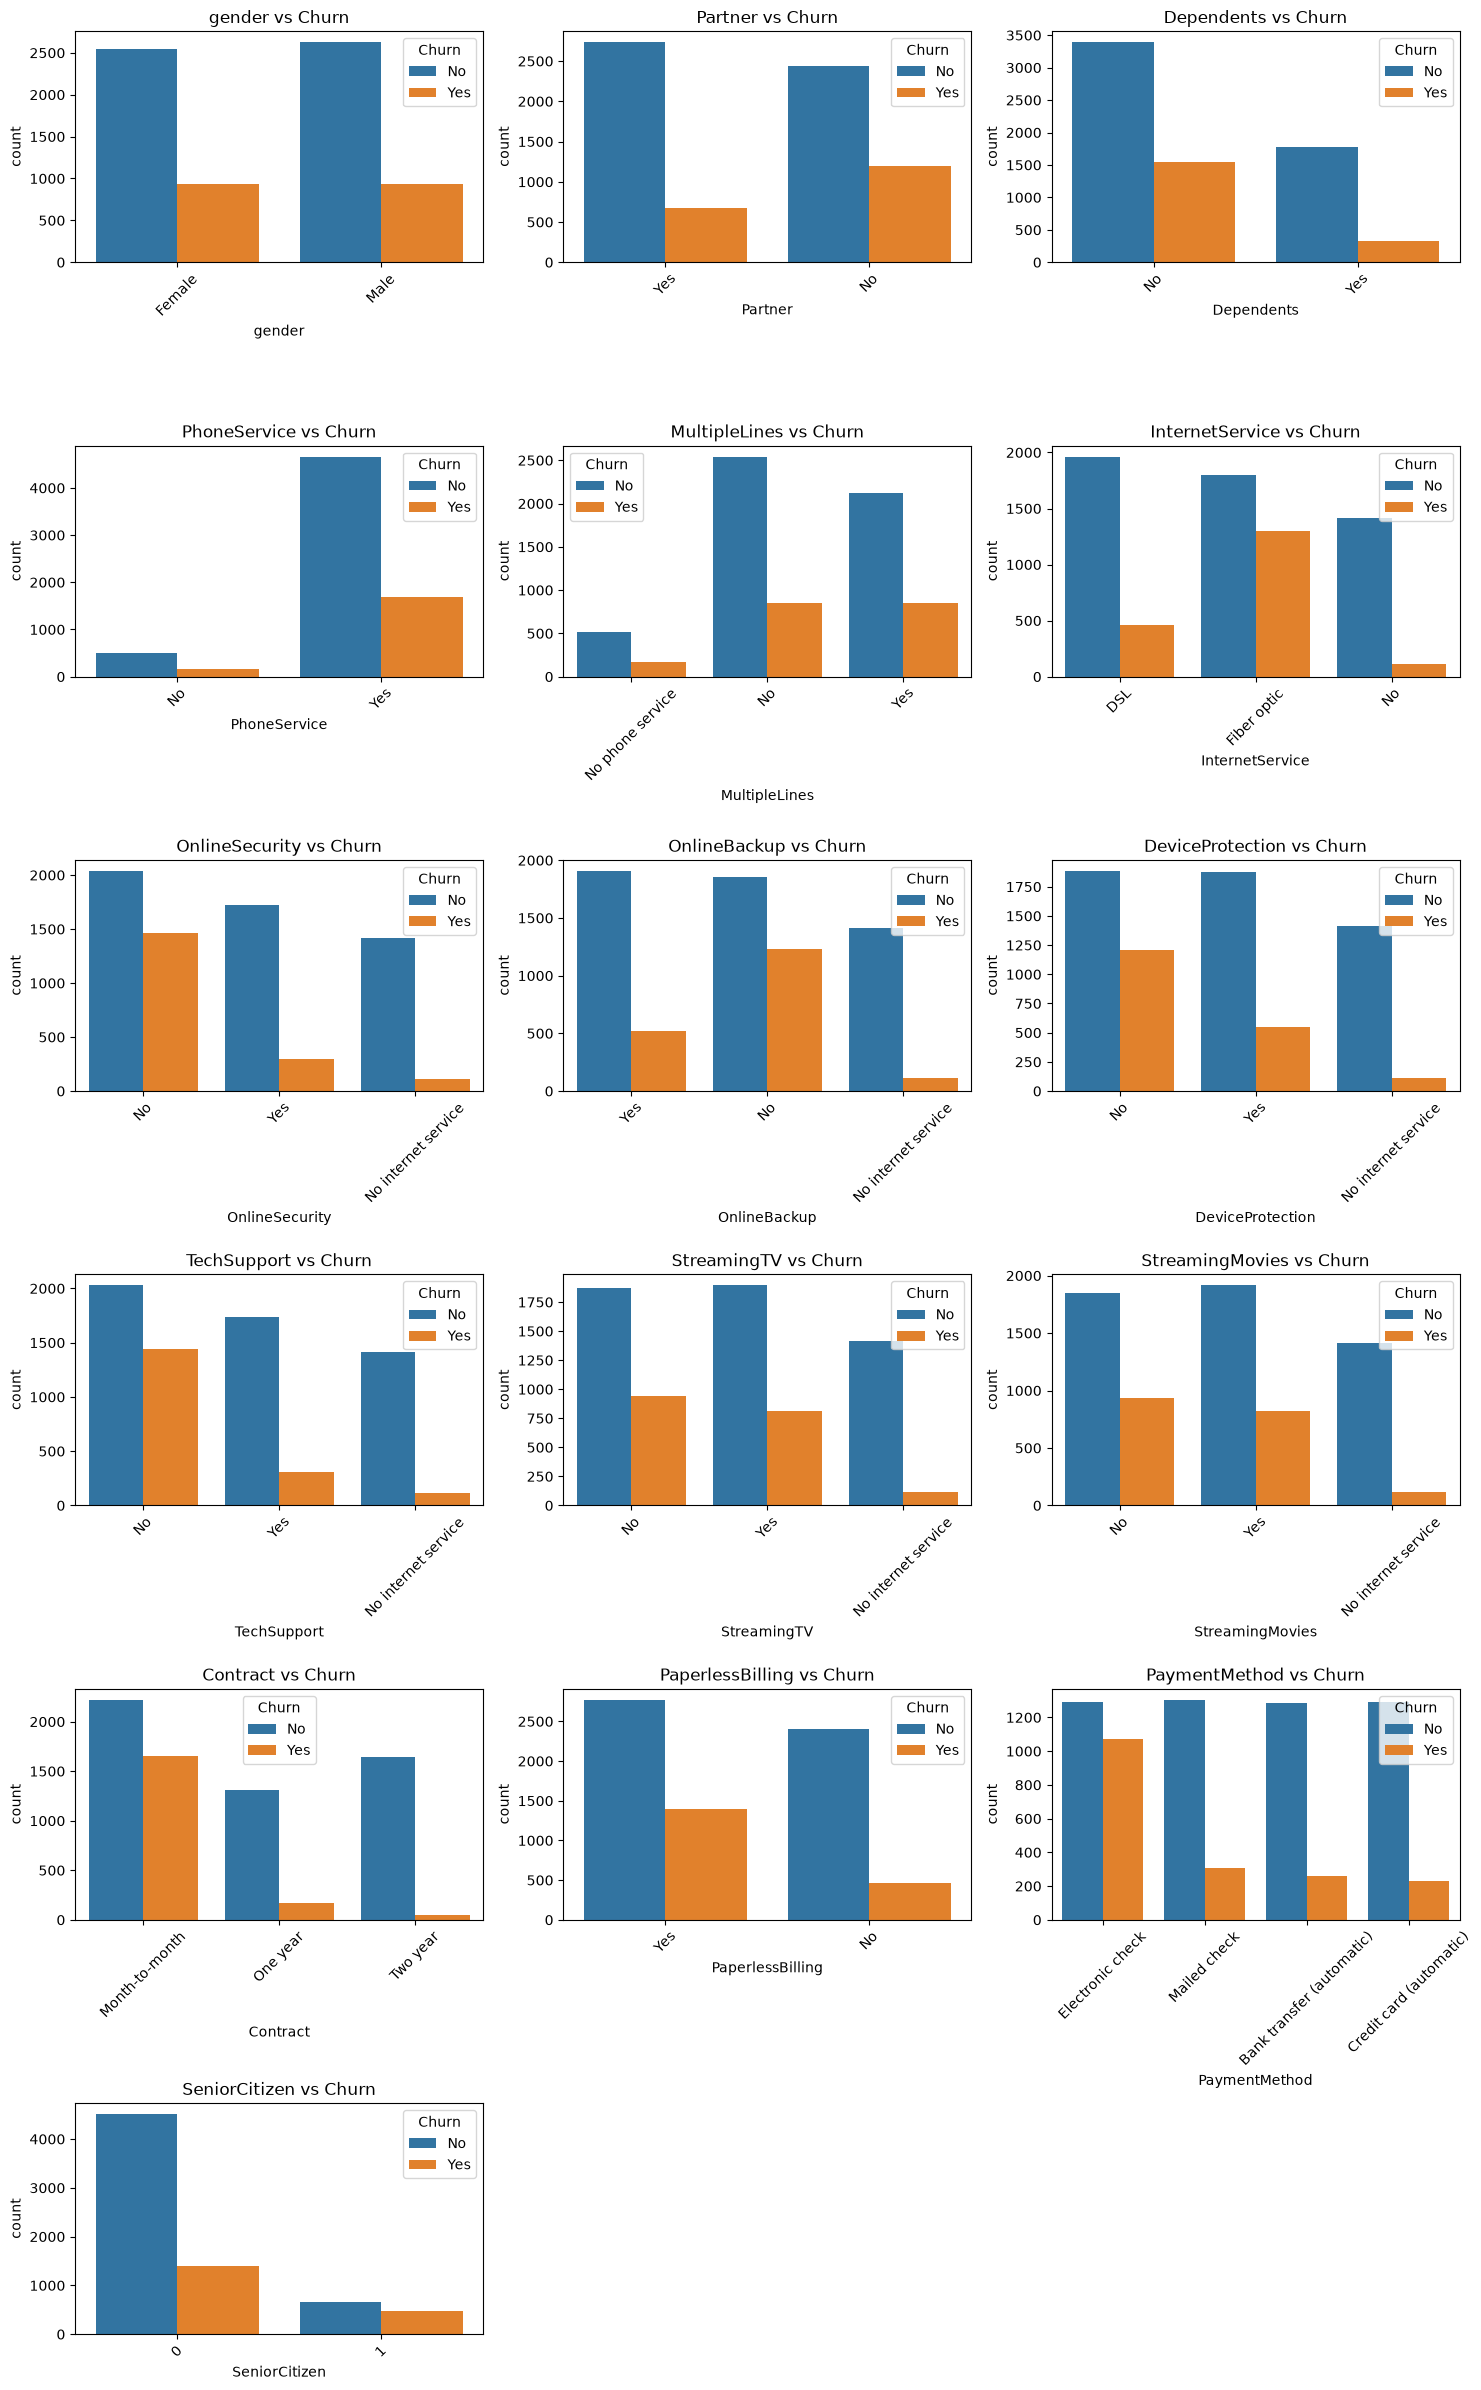

In [23]:
import math

n = len(categorical_features)
cols = 3
rows = math.ceil(n / cols)

fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 4))

for i, feature in enumerate(categorical_features):
    
    sns.countplot(
        data=df,
        x=feature,
        hue="Churn",
        ax=axes.flat[i]
    )
    
    axes.flat[i].set_title(f"{feature} vs Churn")
    axes.flat[i].tick_params(axis="x", rotation=45)

for i in range(n, rows * cols):
    axes.flat[i].set_visible(False)

plt.tight_layout()
plt.show()

In [24]:
for feature in categorical_features:
    print(f"\n{feature}")
    print(
        pd.crosstab(
            df[feature],
            df["Churn"],
            normalize="index"
        ) * 100
    )


gender
Churn          No        Yes
gender                      
Female  73.079128  26.920872
Male    73.839662  26.160338

Partner
Churn           No        Yes
Partner                      
No       67.042021  32.957979
Yes      80.335097  19.664903

Dependents
Churn              No        Yes
Dependents                      
No          68.720860  31.279140
Yes         84.549763  15.450237

PhoneService
Churn                No        Yes
PhoneService                      
No            75.073314  24.926686
Yes           73.290363  26.709637

MultipleLines
Churn                    No        Yes
MultipleLines                         
No                74.955752  25.044248
No phone service  75.073314  24.926686
Yes               71.390104  28.609896

InternetService
Churn                   No        Yes
InternetService                      
DSL              81.040892  18.959108
Fiber optic      58.107235  41.892765
No               92.595020   7.404980

OnlineSecurity
Churn           

In [25]:

churn_rates = {}

for feature in categorical_features:
    rates = df.groupby(feature)["Churn"].apply(
        lambda x: (x == "Yes").mean() * 100
    )
    
    churn_rates[feature] = rates.max() - rates.min()

ranking = pd.Series(churn_rates).sort_values(ascending=False)

print(ranking)

Contract            39.877819
InternetService     34.487785
OnlineSecurity      34.361744
TechSupport         34.230493
OnlineBackup        32.523776
DeviceProtection    31.722645
PaymentMethod       30.042311
StreamingMovies     26.275451
StreamingTV         26.118151
SeniorCitizen       18.075092
PaperlessBilling    17.235009
Dependents          15.828904
Partner             13.293076
MultipleLines        3.683209
PhoneService         1.782951
gender               0.760534
dtype: float64


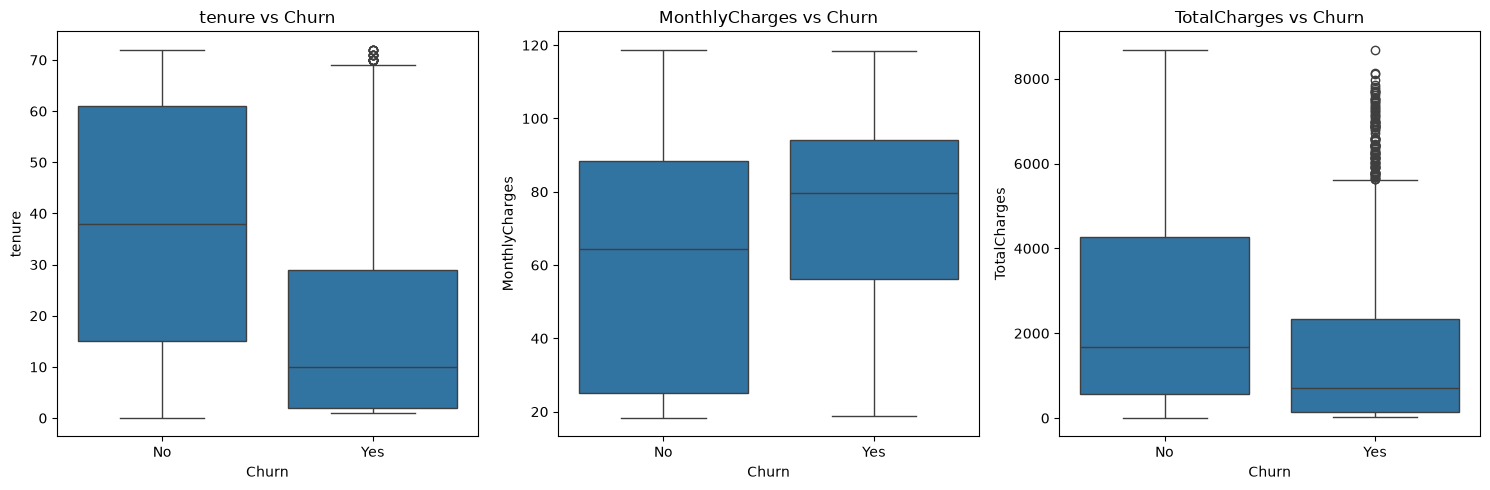

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, feature in enumerate(numerical_features):
    sns.boxplot(data=df, x="Churn", y=feature, ax=axes[i])
    axes[i].set_title(f"{feature} vs Churn")

plt.tight_layout()
plt.show()

In [27]:
correlation = df[numerical_features].corr()

print(correlation)

                  tenure  MonthlyCharges  TotalCharges
tenure          1.000000        0.247900      0.826178
MonthlyCharges  0.247900        1.000000      0.651174
TotalCharges    0.826178        0.651174      1.000000


In [28]:
df.drop(columns=["customerID"], inplace=True)

In [29]:
df_clean = df.copy()

In [30]:
df_clean = df.copy()



df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(0)


df_clean.drop_duplicates(inplace=True)

df_clean["Churn"] = df_clean["Churn"].map({
    "Yes": 1,
    "No": 0
})

print(df_clean.info())
print(df_clean.isnull().sum())
print(df_clean.duplicated().sum())

<class 'pandas.DataFrame'>
Index: 7021 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7021 non-null   str    
 1   SeniorCitizen     7021 non-null   int64  
 2   Partner           7021 non-null   str    
 3   Dependents        7021 non-null   str    
 4   tenure            7021 non-null   int64  
 5   PhoneService      7021 non-null   str    
 6   MultipleLines     7021 non-null   str    
 7   InternetService   7021 non-null   str    
 8   OnlineSecurity    7021 non-null   str    
 9   OnlineBackup      7021 non-null   str    
 10  DeviceProtection  7021 non-null   str    
 11  TechSupport       7021 non-null   str    
 12  StreamingTV       7021 non-null   str    
 13  StreamingMovies   7021 non-null   str    
 14  Contract          7021 non-null   str    
 15  PaperlessBilling  7021 non-null   str    
 16  PaymentMethod     7021 non-null   str    
 17  MonthlyChar

In [31]:
print("Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nDuplicates:")
print(df_clean.duplicated().sum())

print("\nTarget:")
print(df_clean["Churn"].value_counts())

Shape: (7021, 20)

Missing Values:
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicates:
0

Target:
Churn
0    5164
1    1857
Name: count, dtype: int64


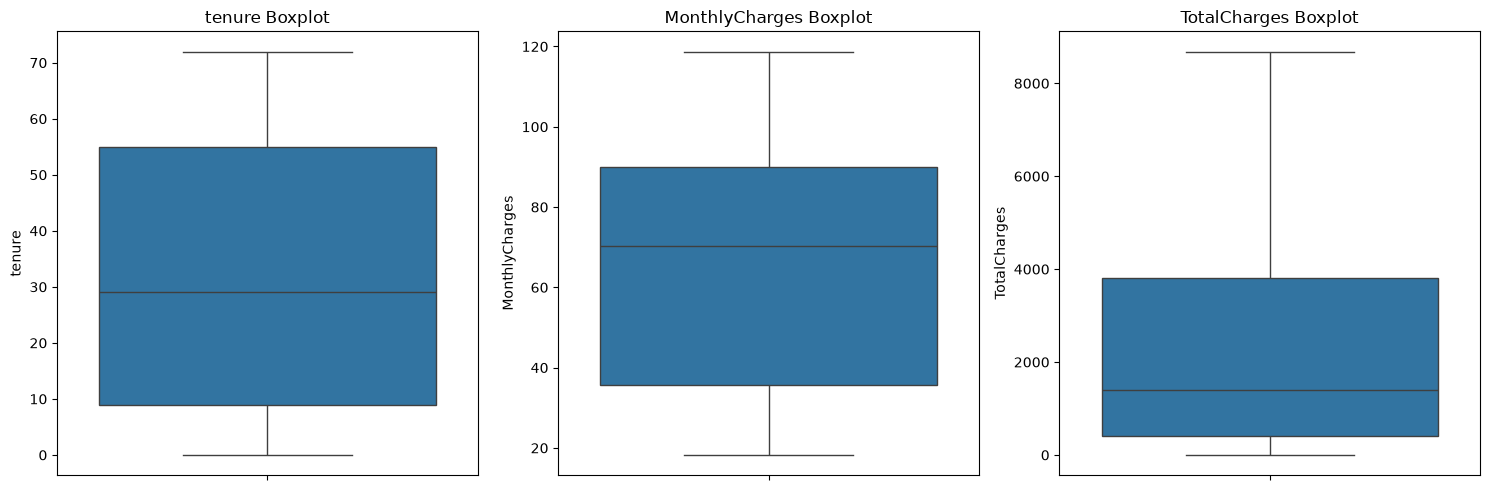

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, feature in enumerate(numerical_features):
    sns.boxplot(data=df_clean, y=feature, ax=axes[i])
    axes[i].set_title(f"{feature} Boxplot")

plt.tight_layout()
plt.show()

In [33]:
df_clean.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn
count,7021.000000,7021.000000,7021.000000,7021.000000,7021.000000
mean,0.162512,32.469449,64.851894,2286.765026,0.264492
std,0.368947,24.534965,30.069001,2266.855057,0.441094
min,0.000000,0.000000,18.250000,0.000000,0.000000
25%,0.000000,9.000000,35.750000,403.350000,0.000000
50%,0.000000,29.000000,70.400000,1400.550000,0.000000
75%,0.000000,55.000000,89.900000,3801.700000,1.000000
max,1.000000,72.000000,118.750000,8684.800000,1.000000


In [34]:
df_clean.head(10)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1
5,Female,0,No,No,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,1
6,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.40,0
7,Female,0,No,No,10,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.90,0
8,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,1
9,Male,0,No,Yes,62,Yes,No,DSL,Yes,Yes,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,0


In [35]:
from sklearn.model_selection import train_test_split


train_df, temp_df = train_test_split(
    df_clean,
    test_size=0.30,
    random_state=42,
    stratify=df_clean["Churn"]
)


val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["Churn"]
)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (4914, 20)
Validation: (1053, 20)
Test: (1054, 20)


In [36]:
train_df.to_csv("train.csv", index=False)
val_df.to_csv("val.csv", index=False)
test_df.to_csv("test.csv", index=False)

In [38]:

df_clean["NumServices"] = (
    (df_clean["PhoneService"] == "Yes").astype(int) +
    (df_clean["OnlineSecurity"] == "Yes").astype(int) +
    (df_clean["OnlineBackup"] == "Yes").astype(int) +
    (df_clean["DeviceProtection"] == "Yes").astype(int) +
    (df_clean["TechSupport"] == "Yes").astype(int) +
    (df_clean["StreamingTV"] == "Yes").astype(int) +
    (df_clean["StreamingMovies"] == "Yes").astype(int)
)

In [39]:
print(df_clean[["NumServices", "Churn"]].head(10))

   NumServices  Churn
0            1      0
1            3      0
2            3      1
3            3      0
4            1      1
5            4      1
6            3      0
7            1      0
8            5      1
9            3      0


In [40]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df_clean,
    test_size=0.30,
    random_state=42,
    stratify=df_clean["Churn"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["Churn"]
)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (4914, 21)
Validation: (1053, 21)
Test: (1054, 21)


In [41]:
train_df.to_csv("train_new.csv", index=False)
val_df.to_csv("val_new.csv", index=False)
test_df.to_csv("test_new.csv", index=False)

In [57]:
df_clean.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn', 'NumServices'],
      dtype='str')

In [58]:
# =========================
# Feature Engineering
# =========================

# 1. Security services count
df_clean["SecurityServices"] = (
    (df_clean["OnlineSecurity"] == "Yes").astype(int) +
    (df_clean["OnlineBackup"] == "Yes").astype(int) +
    (df_clean["DeviceProtection"] == "Yes").astype(int) +
    (df_clean["TechSupport"] == "Yes").astype(int)
)

# 2. Streaming services count
df_clean["StreamingServices"] = (
    (df_clean["StreamingTV"] == "Yes").astype(int) +
    (df_clean["StreamingMovies"] == "Yes").astype(int)
)

# 3. Has Internet
df_clean["HasInternet"] = (
    df_clean["InternetService"] != "No"
).astype(int)

# 4. Has support or security
df_clean["HasSupportOrSecurity"] = (
    (df_clean["TechSupport"] == "Yes") |
    (df_clean["OnlineSecurity"] == "Yes")
).astype(int)

# 5. Average monthly spend
df_clean["AvgMonthlySpend"] = (
    df_clean["TotalCharges"] / (df_clean["tenure"] + 1)
)

# 6. Tenure group
df_clean["TenureGroup"] = pd.cut(
    df_clean["tenure"],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=["0-6", "7-12", "13-24", "25-48", "49-72"]
)

# 7. Contract + Internet
df_clean["Contract_Internet"] = (
    df_clean["Contract"] + "_" +
    df_clean["InternetService"]
)

# 8. Contract + Payment
df_clean["Contract_Payment"] = (
    df_clean["Contract"] + "_" +
    df_clean["PaymentMethod"]
)

# 9. Charge per service
df_clean["ChargePerService"] = (
    df_clean["MonthlyCharges"] /
    (df_clean["NumServices"] + 1)
)

# 10. New customer + monthly contract
df_clean["NewCustomer_MonthlyContract"] = (
    (df_clean["tenure"] <= 6) &
    (df_clean["Contract"] == "Month-to-month")
).astype(int)

In [61]:
df_clean.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn', 'NumServices',
       'SecurityServices', 'StreamingServices', 'HasInternet',
       'HasSupportOrSecurity', 'AvgMonthlySpend', 'TenureGroup',
       'Contract_Internet', 'Contract_Payment', 'ChargePerService',
       'NewCustomer_MonthlyContract'],
      dtype='str')

In [62]:
from sklearn.model_selection import train_test_split

train_data, temp_data = train_test_split(
    df_clean,
    test_size=0.30,
    random_state=42,
    stratify=df_clean["Churn"]
)

val_data, test_data = train_test_split(
    temp_data,
    test_size=0.50,
    random_state=42,
    stratify=temp_data["Churn"]
)

print("Train:", train_data.shape)
print("Validation:", val_data.shape)
print("Test:", test_data.shape)

Train: (4914, 31)
Validation: (1053, 31)
Test: (1054, 31)


In [63]:
train_data.to_csv("train_feature_engineered.csv", index=False)
val_data.to_csv("val_feature_engineered.csv", index=False)
test_data.to_csv("test_feature_engineered.csv", index=False)

In [ ]:

)

Train: (4914, 21)
Validation: (1053, 21)
Test: (1054, 21)
